In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
df = pd.read_csv('superstore.csv', encoding='latin1')
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
9990,9991,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332
9991,9992,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932
9992,9993,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200


# Task 1

In [38]:
# Preparing For Graphs

# Converting to date time
df['Order Date'] = pd.to_datetime(df['Order Date'])
# Creating a month column using dt.month
df['Month'] = df['Order Date'].dt.month
# Group by month using sales
monthly_sales = df.groupby('Month')['Sales'].sum()


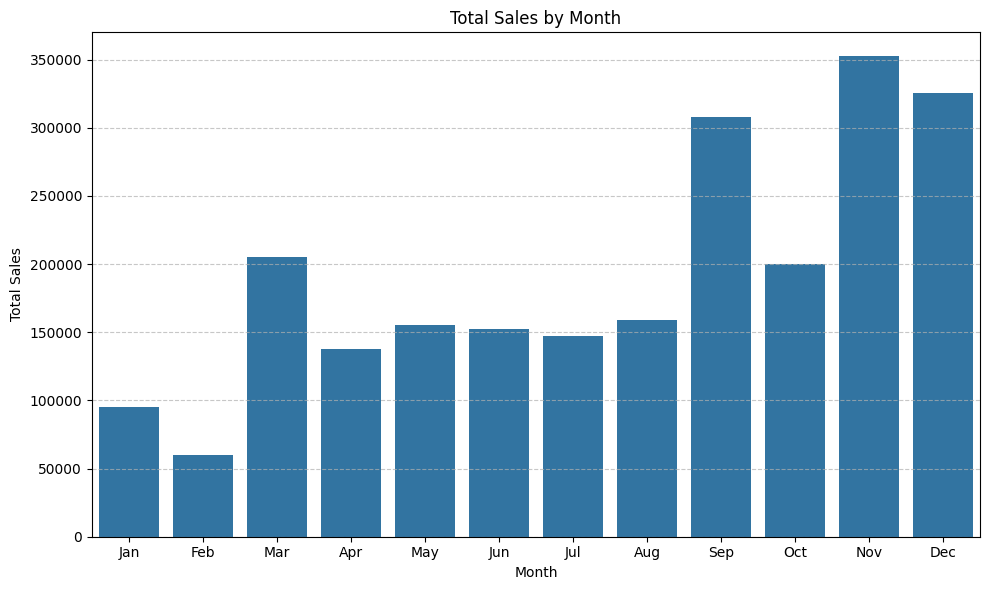

In [39]:
# Bar chart for sales by month - Useful when you want to compare sales between individual months, see clear difference between highest and lowest values.

plt.figure(figsize=(10, 6))
sns.barplot(x = monthly_sales.index, y = monthly_sales.values)
plt.title('Total Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

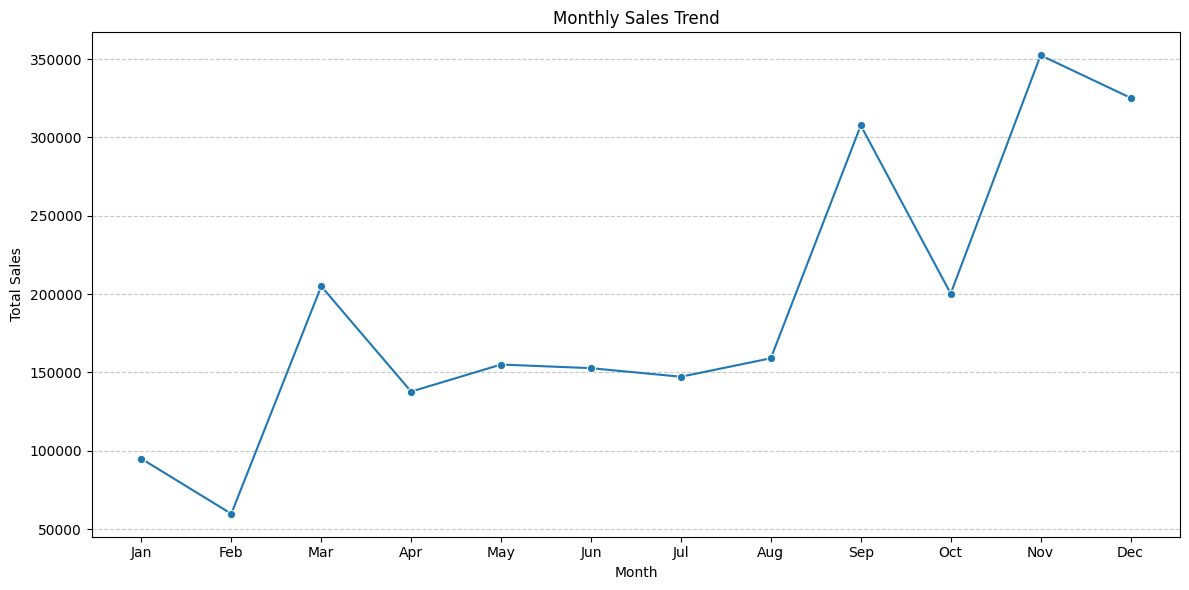

In [40]:
# Line Chart of monthly sales - useful when you want to show increasing and decreasing trends over time (months).

plt.figure(figsize=(12, 6))
sns.lineplot(x = monthly_sales.index, y = monthly_sales.values, marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(ticks=range(1, 13), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

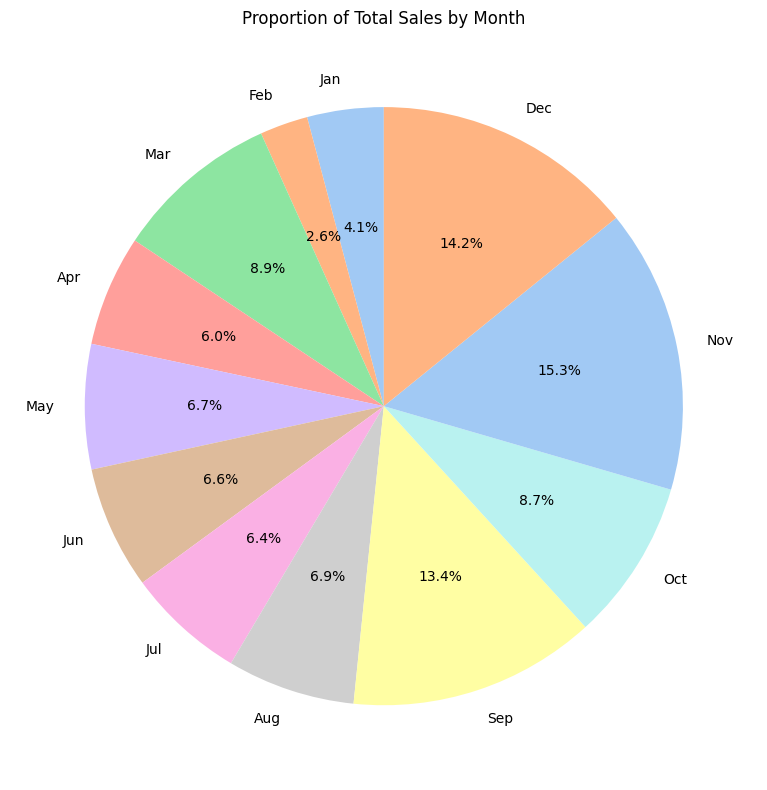

In [56]:
# Pie Chart of Monthly Sales - not recommended for showing overall yearly sales into months due to larger number of slices, only use it if your question is "How much each slice contributes to whole data".

plt.figure(figsize=(10, 8))
plt.pie(monthly_sales, labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
plt.title('Proportion of Total Sales by Month')
plt.tight_layout()
plt.show()

# Task 2


/tmp/ipykernel_1560/1119674504.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = top_5_sub_categories.index, y = top_5_sub_categories.values, palette='viridis')


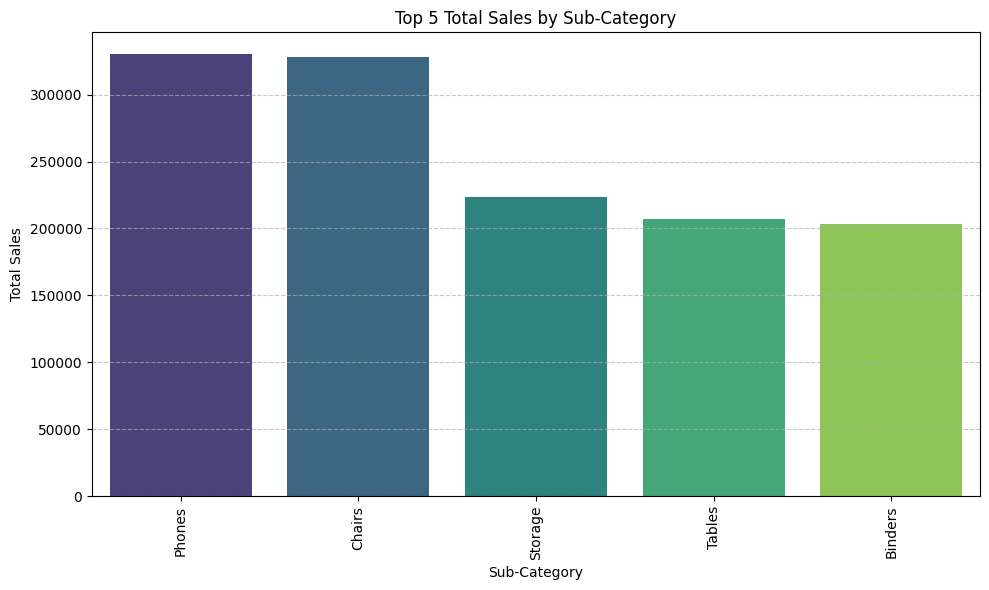

In [44]:
# 2.1
monthly_sales2 = df.groupby('Sub-Category')['Sales'].sum()

# Get top 5 sub-categories
top_5_sub_categories = monthly_sales2.nlargest(5)

plt.figure(figsize=(10, 6))
sns.barplot(x = top_5_sub_categories.index, y = top_5_sub_categories.values, palette='viridis')
plt.title('Top 5 Total Sales by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

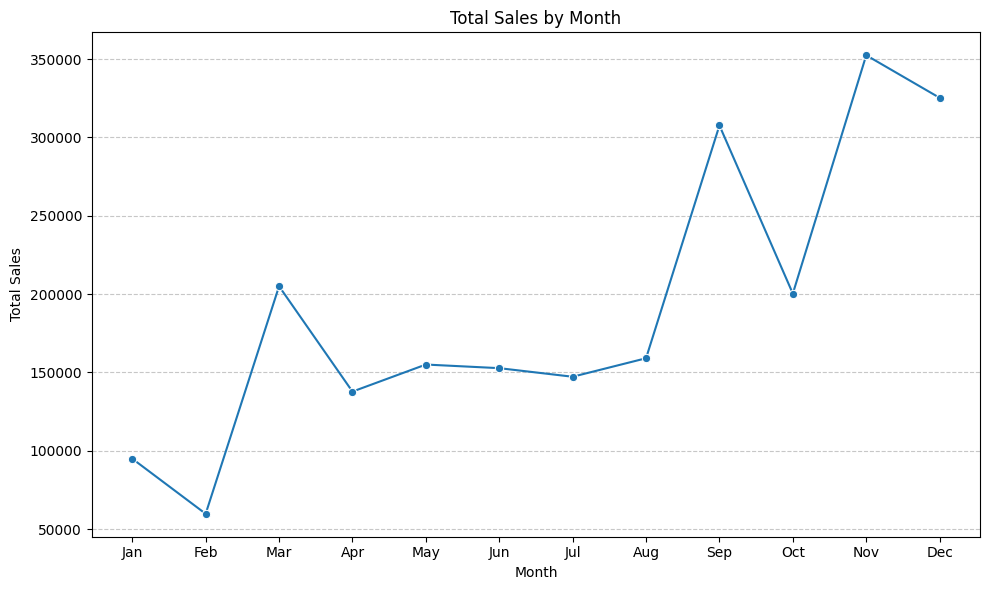

In [49]:
# 2.2 - Show the revenue trend over time

plt.figure(figsize=(10, 6))
sns.lineplot(x = monthly_sales.index, y = monthly_sales.values, marker='o')
plt.title('Total Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(ticks=range(1, 13), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

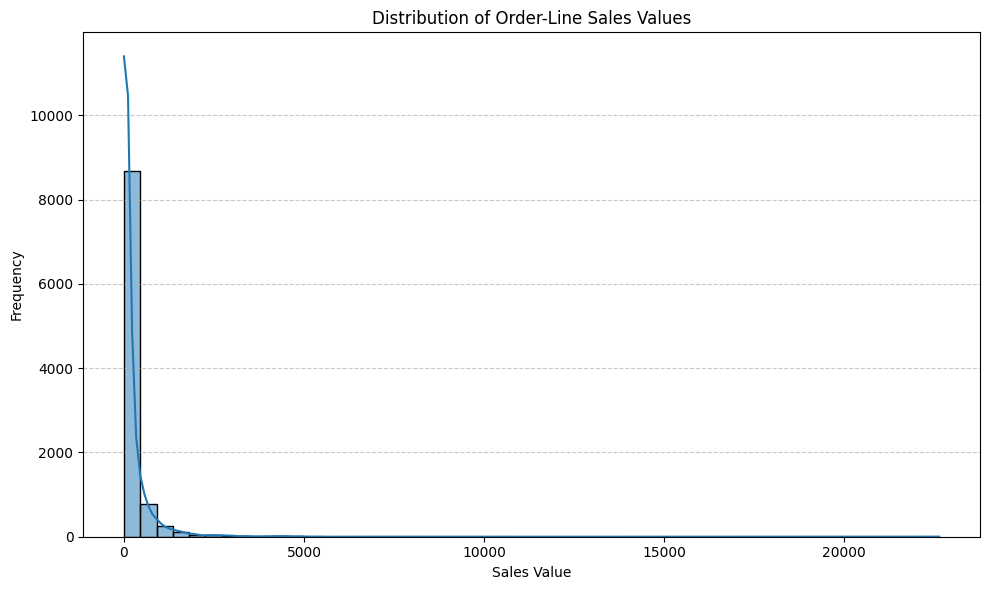

In [45]:
# 2.3 - Show the distribution of order-line sales values

plt.figure(figsize=(10, 6))
sns.histplot(df['Sales'], bins=50, kde=True)
plt.title('Distribution of Order-Line Sales Values')
plt.xlabel('Sales Value')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

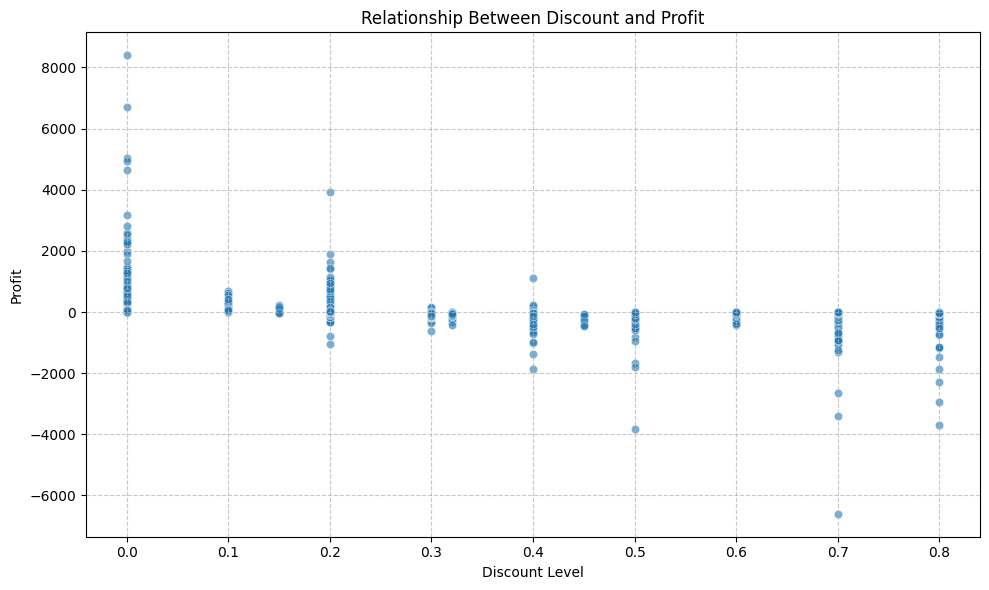

In [57]:
# 2.4 - Show the relationship between discount level and profit

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Discount', y='Profit', data=df, alpha=0.6)
plt.title('Relationship Between Discount and Profit')
plt.xlabel('Discount Level')
plt.ylabel('Profit')
plt.grid(axis='both', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Task 3

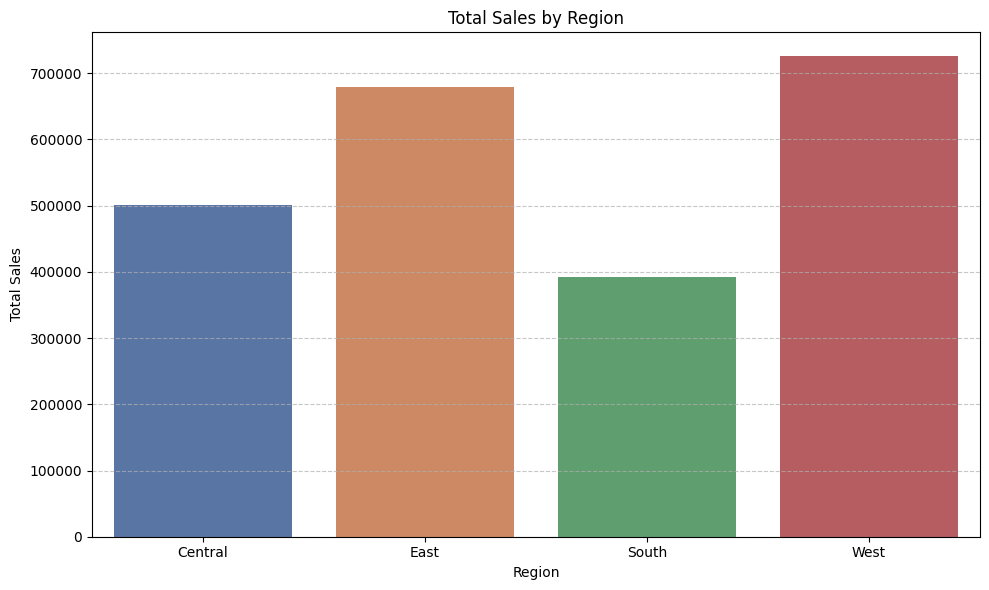

In [62]:
# 3.1
sales_by_region = df.groupby('Region')['Sales'].sum()

plt.figure(figsize=(10, 6))
sns.barplot(x = sales_by_region.index, y = sales_by_region, palette='deep', hue=sales_by_region.index, legend=False)
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

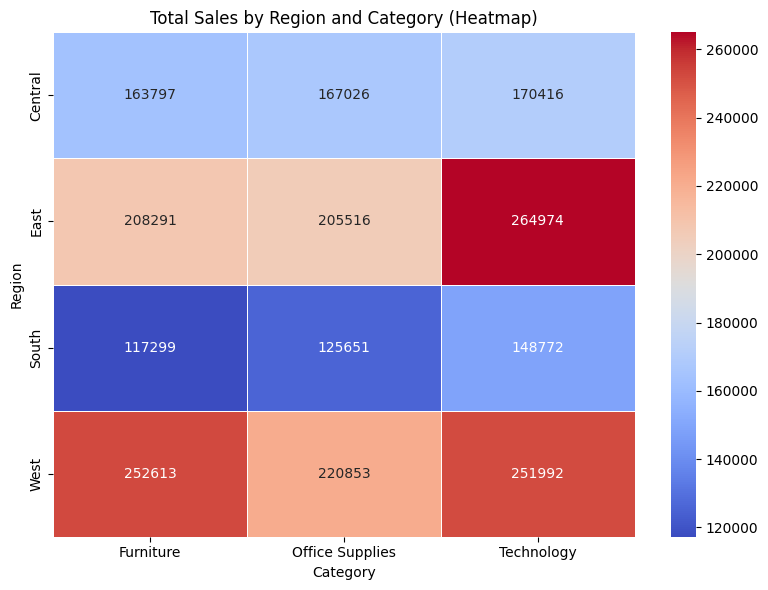

In [66]:
# 3.2 - Group sales by Region and Category
sales_by_region_category = df.groupby(['Region', 'Category'])['Sales'].sum().unstack()

plt.figure(figsize=(8, 6))
sns.heatmap(sales_by_region_category, annot=True, fmt='.0f', cmap='coolwarm', linewidths=.5)
plt.title('Total Sales by Region and Category (Heatmap)')
plt.xlabel('Category')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

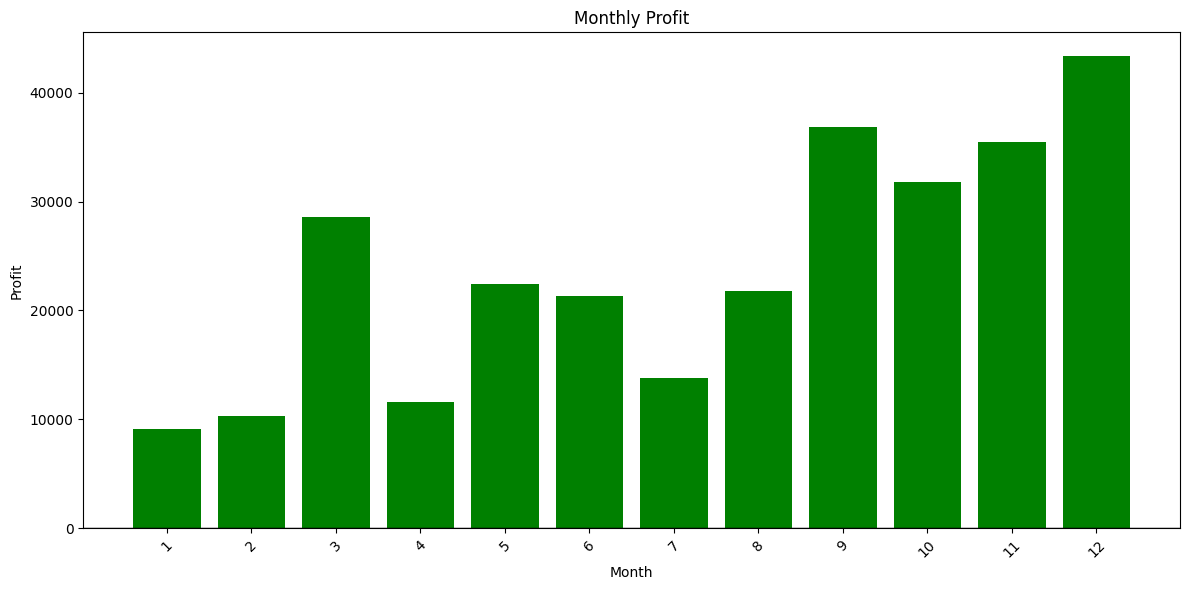

In [78]:
# 3.3 - Total profit by month with diverging colors

# Group by month using profit and convert to DataFrame
monthly_profit = df.groupby('Month')['Profit'].sum().reset_index()

# Iterate over the 'Profit' column to determine colors
colors = ["red" if x < 0 else "green" for x in monthly_profit['Profit']]

plt.figure(figsize=(12, 6))
plt.bar(monthly_profit['Month'].astype(str),
        monthly_profit['Profit'],
        color=colors)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Month")
plt.ylabel("Profit")
plt.title("Monthly Profit")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Task 4:

In [77]:
# Part A
def relative_luminance(rgb):
    values = []

    for c in rgb:
        c = c / 255

        if c <= 0.03928:
            c = c / 12.92
        else:
            c = ((c + 0.055) / 1.055) ** 2.4

        values.append(c)

    R, G, B = values

    return 0.2126 * R + 0.7152 * G + 0.0722 * B



def contrast_ratio(rgb1, rgb2):
    L1 = relative_luminance(rgb1)
    L2 = relative_luminance(rgb2)

    lighter = max(L1, L2)
    darker = min(L1, L2)

    return (lighter + 0.05) / (darker + 0.05)


colors = {
    "red": (255, 0, 0),
    "green": (0, 128, 0),
    "blue": (0, 0, 255),
    "gray": (128, 128, 128)
}

background = (255, 255, 255)

for name, rgb in colors.items():
    ratio = contrast_ratio(rgb, background)

    if ratio >= 4.5:
        result = "PASS"
    else:
        result = "FAIL"

    print(f"{name}: {ratio:.2f}:1 → {result}")

red: 4.00:1 → FAIL
green: 5.14:1 → PASS
blue: 8.59:1 → PASS
gray: 3.95:1 → FAIL


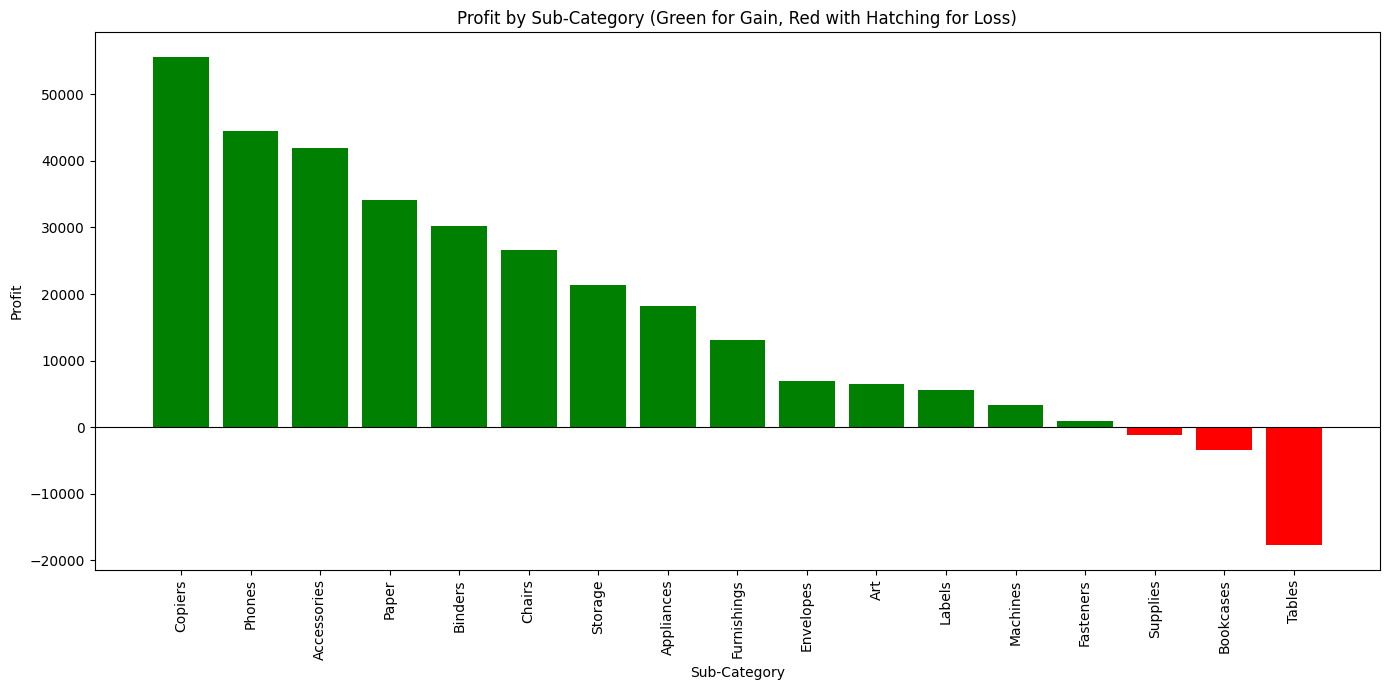

In [80]:
# Part b:
profit_by_subcategory = df.groupby('Sub-Category')['Profit'].sum().reset_index()
# Sort for better visualization, showing highest profit to highest loss
profit_by_subcategory = profit_by_subcategory.sort_values(by='Profit', ascending=False)


plt.figure(figsize=(14, 7))
colors = ["green" if x >= 0 else "red" for x in profit_by_subcategory['Profit']]
bars = plt.bar(profit_by_subcategory['Sub-Category'], profit_by_subcategory['Profit'], color=colors)


plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Sub-Category')
plt.ylabel('Profit')
plt.title('Profit by Sub-Category (Green for Gain, Red with Hatching for Loss)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Task 5:

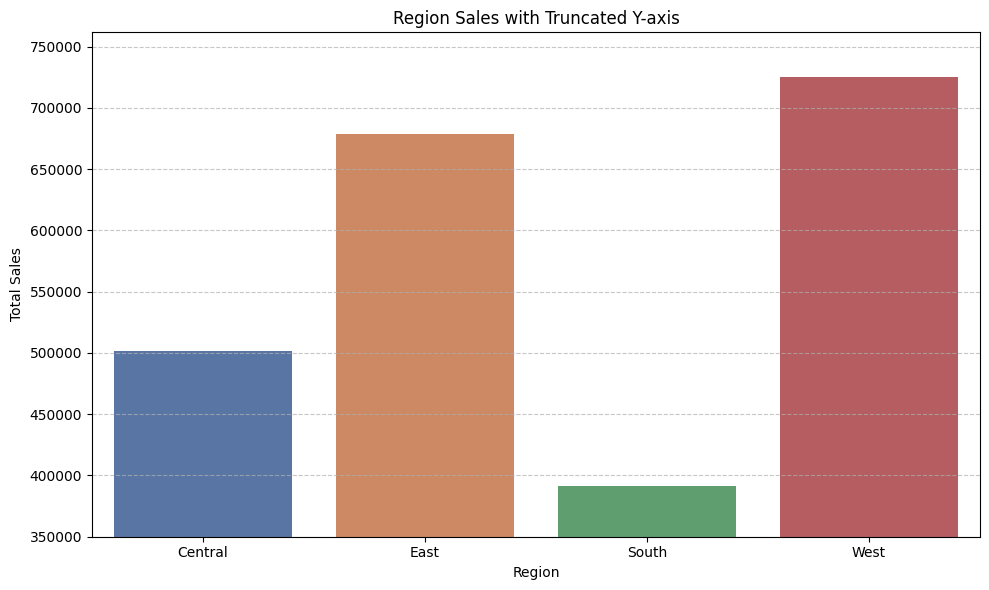

In [82]:
# Truncated Y-axis on Region Sales Chart
plt.figure(figsize=(10, 6))
sns.barplot(x=sales_by_region.index, y=sales_by_region, palette='deep', hue=sales_by_region.index, legend=False)
plt.ylim(350000) # Truncate Y-axis to exaggerate differences
plt.title('Region Sales with Truncated Y-axis')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

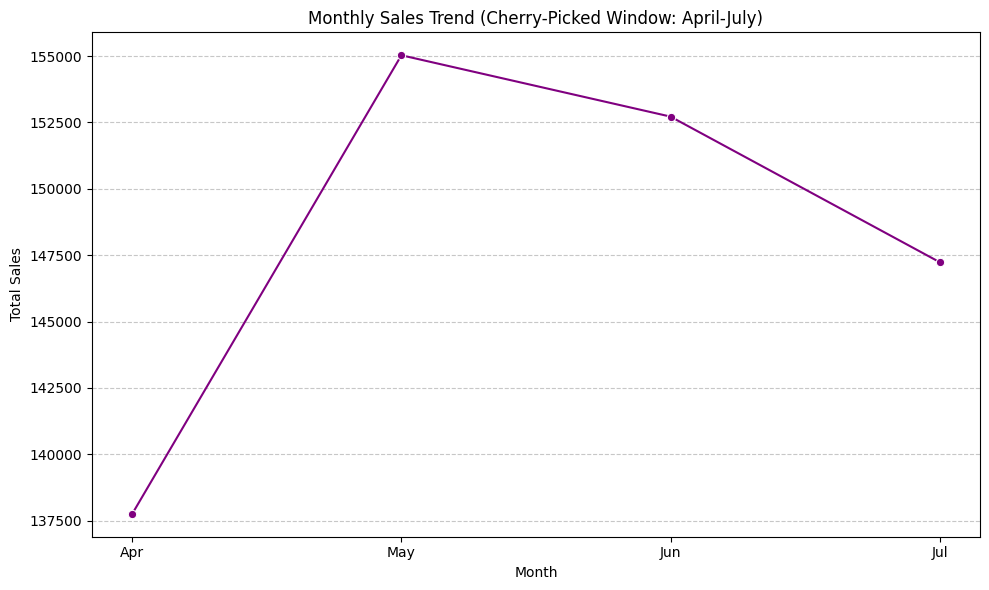

In [83]:
# Cherry-Picked Date Window (Monthly Sales Trend)

# Select a date window, e.g., months 4 to 7 (April to July)
cherry_picked_sales = monthly_sales.loc[4:7]

plt.figure(figsize=(10, 6))
sns.lineplot(x=cherry_picked_sales.index, y=cherry_picked_sales.values, marker='o', color='purple')
plt.title('Monthly Sales Trend (Cherry-Picked Window: April-July)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(ticks=range(4, 8), labels=['Apr', 'May', 'Jun', 'Jul'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

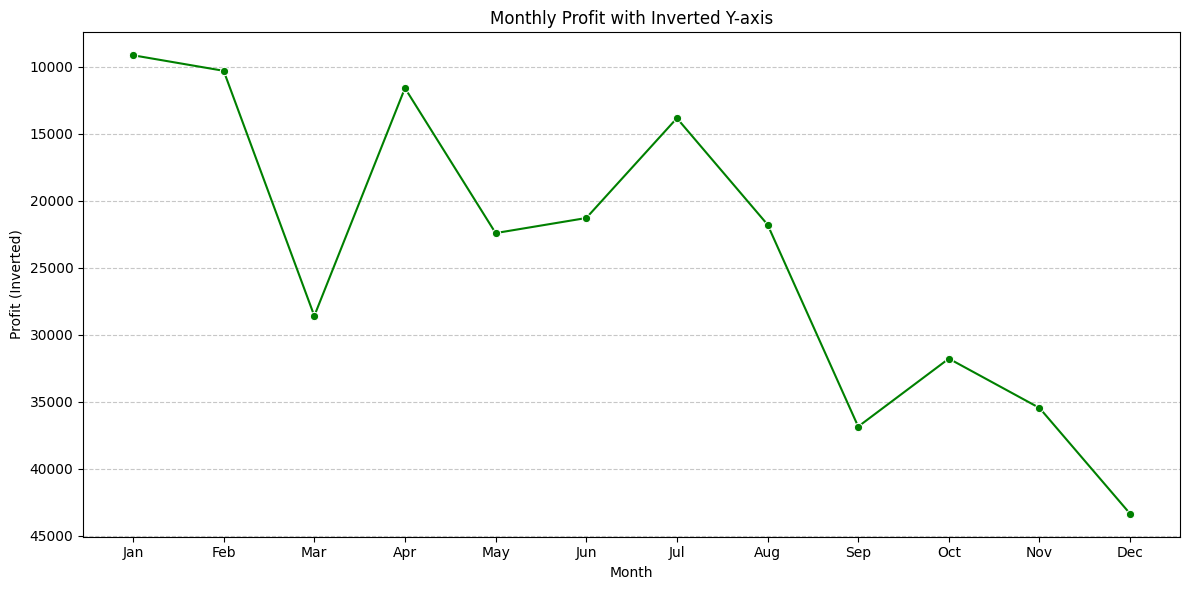

In [84]:
# Inverted Y-axis on Monthly Profit Line
plt.figure(figsize=(12, 6))
sns.lineplot(x=monthly_profit['Month'], y=monthly_profit['Profit'], marker='o', color='green')

plt.gca().invert_yaxis() # Invert the Y-axis

plt.title('Monthly Profit with Inverted Y-axis')
plt.xlabel('Month')
plt.ylabel('Profit (Inverted)')
plt.xticks(ticks=range(1, 13), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Task 6:

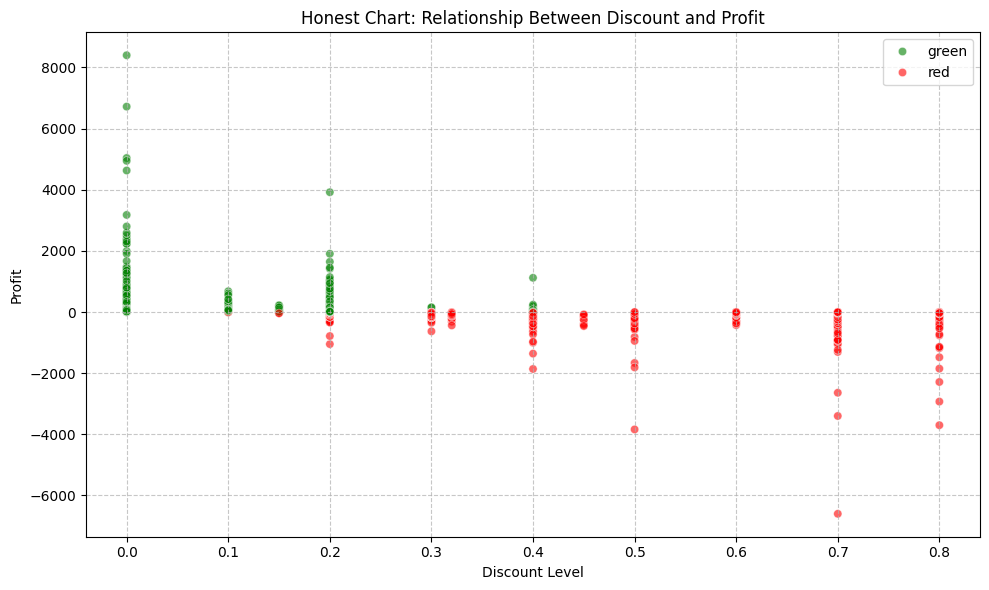

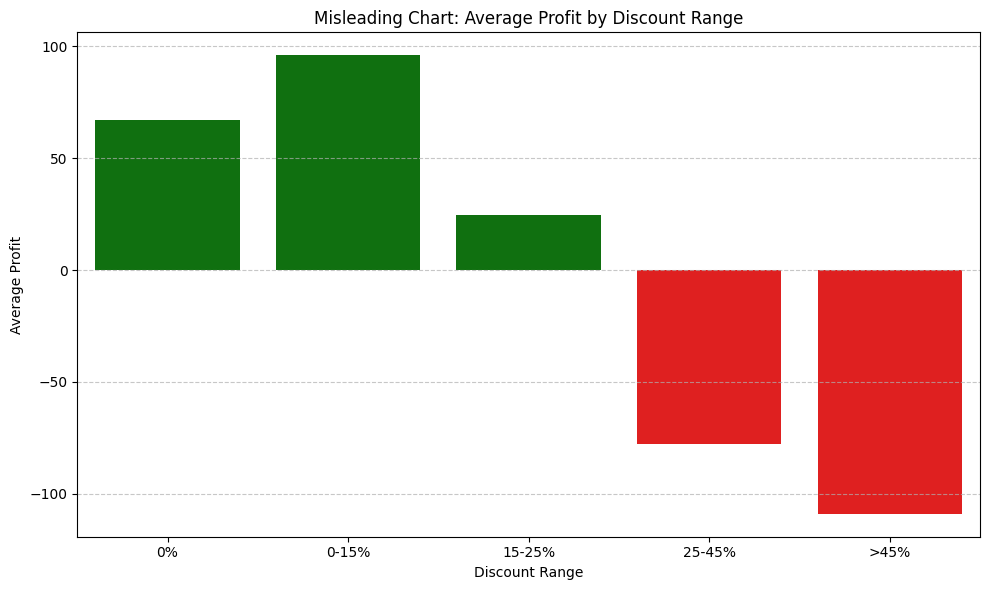

In [86]:
### Honest Chart: Relationship Between Discount and Profit

plt.figure(figsize=(10, 6))
colors = ["green" if profit >= 0 else "red" for profit in df['Profit']]
sns.scatterplot(x='Discount', y='Profit', data=df, alpha=0.6, hue=colors, palette={'green': 'green', 'red': 'red'}, legend='full')
plt.title('Honest Chart: Relationship Between Discount and Profit')
plt.xlabel('Discount Level')
plt.ylabel('Profit')
plt.grid(axis='both', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### Misleading Chart: Average Profit by Discount Range

# Create discount bins
discount_bins = [0, 0.05, 0.15, 0.25, 0.45, 0.8]
discount_labels = ['0%', '0-15%', '15-25%', '25-45%', '>45%'] # Adjust labels based on bins
df['Discount_Range'] = pd.cut(df['Discount'], bins=discount_bins, labels=discount_labels, right=False)

# Calculate average profit per discount range
avg_profit_by_discount_range = df.groupby('Discount_Range', observed=False)['Profit'].mean().reset_index()

plt.figure(figsize=(10, 6))
colors_misleading = ["green" if x >= 0 else "red" for x in avg_profit_by_discount_range['Profit']]
sns.barplot(x='Discount_Range', y='Profit', data=avg_profit_by_discount_range, palette=colors_misleading, hue='Discount_Range', legend=False)
plt.title('Misleading Chart: Average Profit by Discount Range')
plt.xlabel('Discount Range')
plt.ylabel('Average Profit')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Drop the temporary column
df.drop(columns=['Discount_Range'], inplace=True, errors='ignore')